In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/model_db_hay/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/'
from cell_builder_utils import cell_params, _get_dends, _get_pyr_soma, Cell
from mechs_utils import Mechs
from plot_utils import fig_conductances, fig_compartments
from functools import partial

In [2]:
# get paramaters
section_params, end_pts, cell_tree = cell_params()

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L5Pyr', section_names)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr')

mech_class = Mechs(pth_mod)



Rename all gbars and E's so that I can access them efficiently

In [3]:
# make it spike at 100 Hz

all_mechs = ['pas', 'NaT', 'SKv3_1', 'Nap_Et2', 'Ca_HVA', 'Ca_LVAst', 'CaDynamics_E2', 'SK_E2', 'Ih', 'Im', 'K_Pst', 'K_Tst']

# build L5 cell with nap

for num_m in np.arange(2,len(all_mechs)+1,1):

    fig, ax = plt.subplots(2,1,height_ratios=[0.25,1])


    # build L5 cell
    l5pyr= Cell(sections, cell_tree, gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, all_mechs[:num_m])

    stim = [None]*3
    clamp_current = [None]*3
    for i in range(3):
        stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
        stim[i].delay = 5+(10*i)
        stim[i].dur = 1
        stim[i].amp = 10.
        clamp_current[i] = h.Vector().record(stim[i]._ref_i)

    soma_v = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(40 * ms)

    for c in clamp_current:
        ax[0].plot(t,c, color='k')
    
    ax[0].set_ylabel('clamp \n current')
    ax[1].plot(t,soma_v)
    ax[1].set_ylabel('membrane potential ($\mu V$)')

    fig.savefig(figpth + 'hay_crit_freq_spikes_' + '_'.join(all_mechs[:num_m]) + '.png')

    plt.clf()



<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

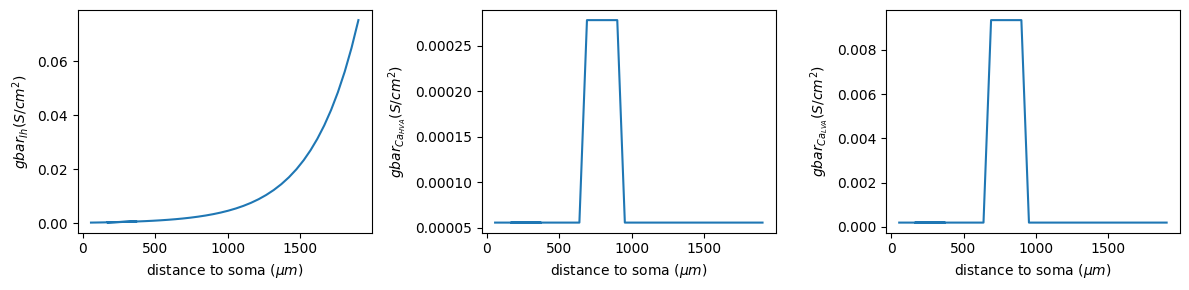

In [4]:
# check that Ih conductances  make sense

fig = fig_conductances(l5pyr)
fig.savefig('hay_distribution_conductances.png')


Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn_dev/model_db_hay/mod.  Aborting.


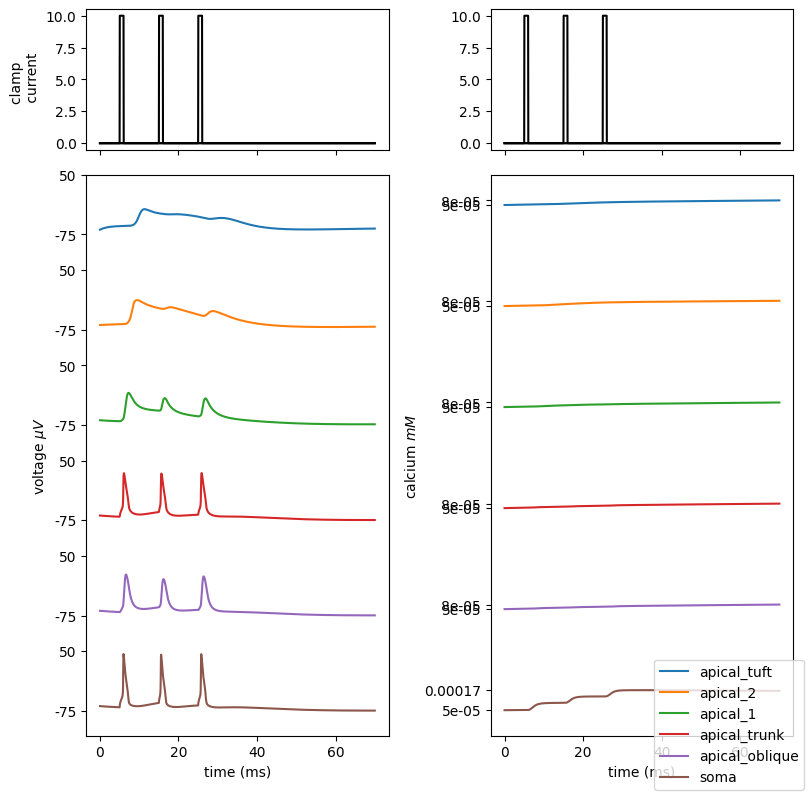

In [5]:
all_mechs = ['pas', 'NaT', 'SKv3_1', 'Nap_Et2', 'Ca_HVA', 'Ca_LVAst', 'CaDynamics_E2', 'Ih', 'Im','SK_E2', 'K_Pst', 'K_Tst']

l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
add_mech = Mechs(pth_mod)
l5pyr = add_mech.add_mechs(l5pyr, mechs=all_mechs, hotzone=[650, 950])

num_pulse = 3
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 5+(10*i)
    stim[i].dur = 1
    stim[i].amp = 10.
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig = fig_compartments(l5pyr, clamp_current, l_stim=70)
fig.savefig(f'hay_sections_{str(num_pulse)}_pulses.png')

## Move hot zone to apical tuft

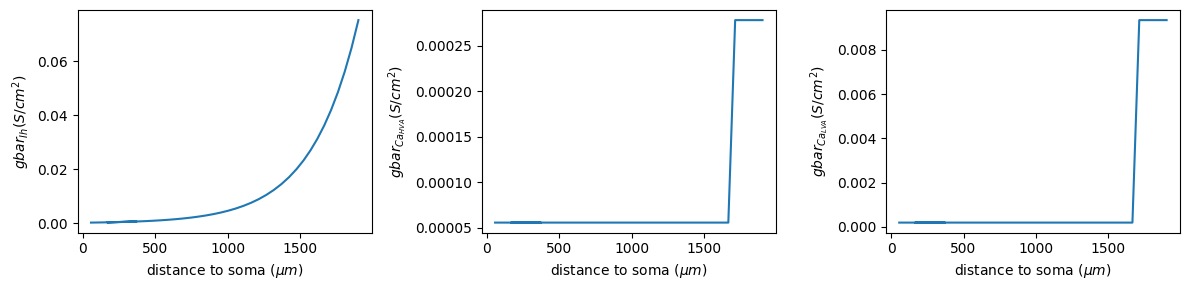

In [6]:
hotzone = [1700, 2000]
l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = add_mech.add_mechs(l5pyr, mechs=all_mechs, hotzone=hotzone)

fig = fig_conductances(l5pyr)
fig.savefig('hay_moved_hot_zone.png')



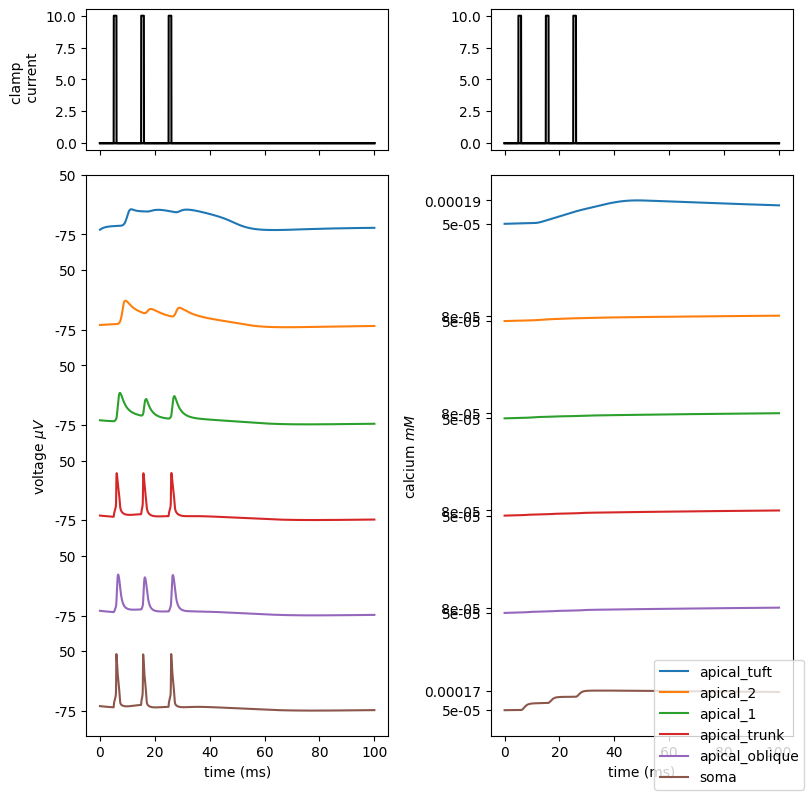

In [7]:
# critical freq
num_pulse = 3
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 5+(10*i)
    stim[i].dur = 1
    stim[i].amp = 10.
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig = fig_compartments(l5pyr, clamp_current, l_stim=100)
fig.savefig(f'hay_sections_{str(num_pulse)}_pulses.png')

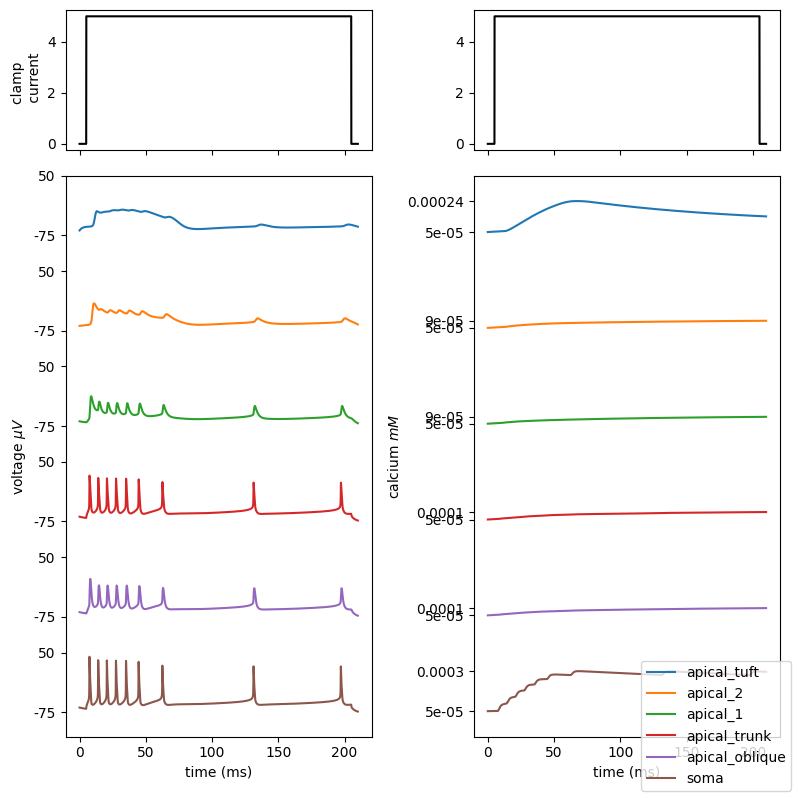

In [8]:
# Continuous input

l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = add_mech.add_mechs(l5pyr, mechs=all_mechs, hotzone=hotzone)

stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 200
stim.amp = 5.
clamp_current = h.Vector().record(stim._ref_i)

fig = fig_compartments(l5pyr, [clamp_current], l_stim=210)
fig.savefig(f'hay_sections_continuous.png')


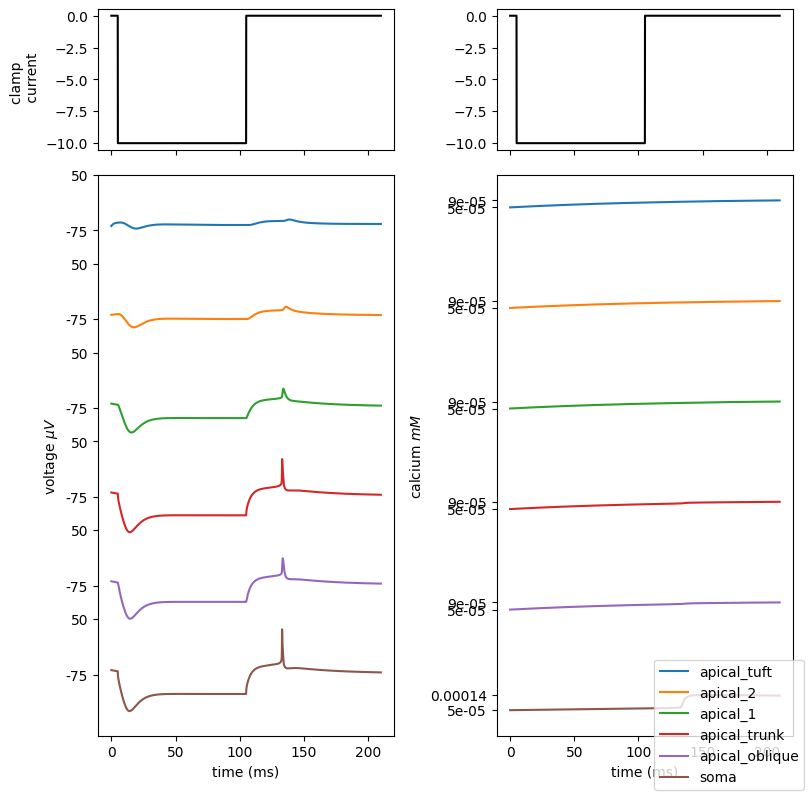

In [9]:
# Hyperpolarizing

l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = add_mech.add_mechs(l5pyr, mechs=all_mechs, hotzone=hotzone)


stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 100
stim.amp = -10.
clamp_current = h.Vector().record(stim._ref_i)

fig = fig_compartments(l5pyr, [clamp_current], l_stim=210)
fig.savefig(f'hay_sections_hyperpolarizing.png')

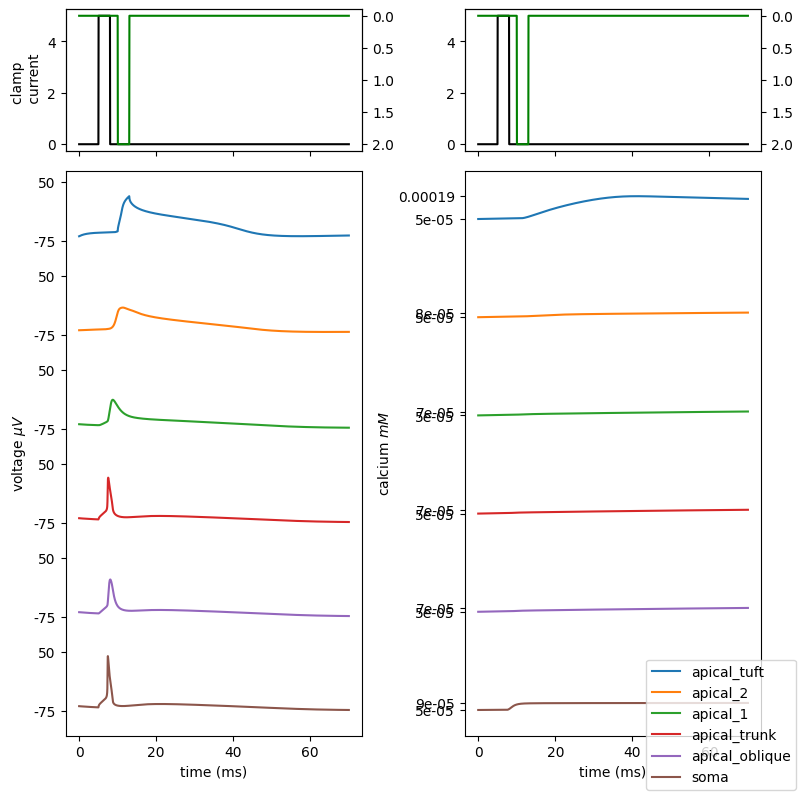

In [10]:
l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = add_mech.add_mechs(l5pyr, mechs=all_mechs, hotzone=hotzone)

stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 5.
clamp_soma = h.Vector().record(stim._ref_i)

stim_a = h.IClamp(l5pyr._nrn_sections['apical_tuft'](0.5))
stim_a.delay = 10
stim_a.dur = 3
stim_a.amp = 2.
clamp_tuft = h.Vector().record(stim_a._ref_i)

section_names = ['apical_tuft', 'apical_2', 'apical_1', 'apical_trunk', 'apical_oblique', 'soma']

l_stim = 70
voltg = [None]*len(section_names)
ca = [None]*len(section_names)
for i, section in enumerate(section_names):
    voltg[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)
    ca[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_cai)

t = h.Vector().record(h._ref_t)


h.celsius = 34
h.finitialize(-65 * mV)
h.continuerun(l_stim * ms)

fig, ax = plt.subplots(2,2, figsize=(8,8), height_ratios=[0.25, 1], sharex=True)

ax[0,0].plot(t, clamp_soma, color='k')
ax2 = ax[0,0].twinx()
ax2.plot(t, clamp_tuft, color='g')
ax2.invert_yaxis()
ax[0,1].plot(t, clamp_soma, color='k')
ax2 = ax[0,1].twinx()
ax2.plot(t, clamp_tuft, color='g')
ax2.invert_yaxis()

ax[0,0].set_ylabel('clamp \n current')
yticks_v = []
yticklabels_v = []

yticks_ca = []
yticklabels_ca = []

cv = 0
cca = 0
for i,section in enumerate(section_names):
    
    ax[1,0].plot(t,voltg[i] + cv)

    yticks_v.append(-75+cv)
    yticks_v.append(50+cv)

    yticklabels_v.append(str(np.round(-75)))
    yticklabels_v.append(str(np.round(50)))

    cv -= 200

    ax[1,1].plot(t,ca[i] + cca, label=section)

    yticks_ca.append(min(ca[i])+cca)
    yticks_ca.append(max(ca[i])+cca)

    yticklabels_ca.append(str(min(ca[i])))
    yticklabels_ca.append(str(np.round(max(ca[i]),5)))

    cca -= 6e-4


ax[1,0].set_yticks(yticks_v)
ax[1,0].set_yticklabels(yticklabels_v)
ax[1,0].set_ylabel('voltage $\mu V$')
ax[1,0].set_xlabel('time (ms)')


ax[1,1].set_yticks(yticks_ca)
ax[1,1].set_yticklabels(yticklabels_ca)
ax[1,1].set_ylabel('calcium $mM$')
ax[1,1].set_xlabel('time (ms)')
fig.legend(loc='lower right')

fig.tight_layout()

fig.savefig(f'hay_sections_coincidence.png')

In [11]:
# check what the different mechanisms do
all_mechs = ['CaDynamics_E2','pas', 'NaT', 'SKv3_1', 'Nap_Et2', 'Ca_HVA', 'Ca_LVAst',  'SK_E2', 'Ih', 'Im', 'K_Pst', 'K_Tst']

num_pulse = 3

for num_m in np.arange(3,len(all_mechs)+1,1):

    l5pyr= Cell(sections, cell_tree, gid=0)
    l5pyr.build()
    l5pyr = add_mech.add_mechs(l5pyr, mechs=all_mechs[:num_m], hotzone=hotzone)
    stim = [None]*num_pulse
    clamp_current = [None]*num_pulse
    for i in range(num_pulse):
        stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
        stim[i].delay = 5+(10*i)
        stim[i].dur = 1
        stim[i].amp = 10.
        clamp_current[i] = h.Vector().record(stim[i]._ref_i)

    fig = fig_compartments(l5pyr, clamp_current, l_stim=100)
    fig.savefig(f'{figpth}hay_sections_{str(num_pulse)}_pulses_'+'_'.join(all_mechs[:num_m])+'.png')
    plt.clf()

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

## Compare gating variables for the different models

In [12]:
q10_hh = 3**((37-6.3)/10)
q10_hh2 = 3**((37-6.3-30.7)/10)
q10_hay = 2.3**((34-21)/10)


In [13]:
def vtrap(x, y):
        import math
        if abs(x/y) > 1e-6:
            return x / (math.exp(x/y) - 1)
        else:
            return y * (1 - x/y/2)  # Taylor series approximation
        
class hnn:

    def __init__(self, q10):
        self.q10 = q10
    

    def na_steady(self,v):
        
        alpha = 0.1 * vtrap(-(v+40),10)
        beta = 4 * np.exp(-(v+65)/18)
        sum = alpha + beta
        mtau = 1/(self.q10*sum)
        minf = alpha/sum

        alpha = .07 * np.exp(-(v+65)/20)
        beta = 1 / (np.exp(-(v+35)/10) + 1)
        sum = alpha + beta
        htau = 1/(self.q10*sum)
        hinf = alpha/sum

        return mtau, minf, htau, hinf

    def k_steady(self,v):

        alpha = .01*vtrap(-(v+55),10) 
        beta = .125*np.exp(-(v+65)/80)
        sum = alpha + beta
        ntau = 1/(self.q10*sum)
        ninf = alpha/sum

        return ntau, ninf
    
    def ar_steady(self, v):
        
        minf  = 1 / ( 1 + np.exp( ( v + 75 ) / 5.5 ) )
        mtau = 1 / ( np.exp( -14.6 - 0.086 * v ) + np.exp( -1.87 + 0.07 * v ) )

        return minf, mtau

    def ca(self, v):
         
         tadj = 2.3**((37-23-30.7)/10)
         a = 0.055 * (-27 - v) / (np.exp((-27 - v) / 3.8) - 1)
         b = 0.94 * np.exp((-75 - v) / 17)
         
         mtau = 1 / tadj / (a+b)
         minf = a / (a + b)

         a = 0.000457 * np.exp((-13 - v) / 50)
         b = 0.0065 / (np.exp((-v - 15) / 28) + 1)

         htau = 1 /  tadj / (a + b)
         hinf = a / (a + b)

         return mtau, minf, htau, hinf
    
    def cat(self, v):
         
         minf  = 1 / (1 + np.exp(( -v - 56 ) / 6.2))
         mtau  = 0.204 + 0.333 / (np.exp(( v + 15.8) / 18.2) + np.exp((-v - 131) / 16.7))
         hinf  = 1 / (1 + np.exp((v + 80) / 4))

         if v < 81:
            htau  = 0.333 * np.exp((v + 466 ) / 66.6)
         else:
            htau  = 9.32 + 0.333 * np.exp((-v - 21) / 10.5)

         return mtau, minf, htau, hinf
    
    def kca(self, cai):

        Ra = 0.1
        Rb = 0.2
        caix = 1
        a = Ra * cai**caix
        b = Rb

        ntau = 1 / self.q10 / (a + b)
        ninf = a / (a + b)

        return ntau, ninf
    
    def km(self, v):

        Ra = .001
        Rb = .001
        tha = -30
        qa = 9

        a = Ra * (v - tha) / (1 - np.exp(-(v - tha) / qa))
        b = -Rb * (v - tha) / (1 - np.exp((v - tha) / qa))

        ntau = 1/self.q10/(a+b)
        ninf = a/(a+b)

        return ntau, ninf


         
         


In [14]:
class hay:

    def __init__(self, q10):
        self.q10 = q10
    
    def na_steady_dend(self,v):
        
        if v == -32:
            v += .0001

        alpha = (0.182 * (v- -32))/(1-(np.exp(-(v - -32)/6)))
        beta = (0.124 * (-v -32))/(1-(np.exp(-(-v -32)/6)))
        sum = alpha + beta
        mtau = (1/sum)/self.q10
        minf = alpha/sum

        if v == -60:
            v += .0001

        alpha = (-0.015 * (v- -60))/(1-(np.exp((v- -60)/6)))
        beta = (-0.015 * (-v -60))/(1-(np.exp((-v -60)/6)))
        sum = alpha + beta
        htau = (1/sum)/self.q10
        hinf = alpha/sum

        return mtau, minf, htau, hinf
    
    def na_steady_soma(self,v):
        
        if v == -38:
            v += .0001

        alpha = (0.182 * (v- -38))/(1-(np.exp(-(v - -38)/6)))
        beta = (0.124 * (-v -38))/(1-(np.exp(-(-v -38)/6)))
        sum = alpha + beta
        mtau = (1/sum)/self.q10
        minf = alpha/sum

        if v == -66:
            v += .0001

        alpha = (-0.015 * (v- -66))/(1-(np.exp((v- -66)/6)))
        beta = (-0.015 * (-v -66))/(1-(np.exp((-v -66)/6)))
        sum = alpha + beta
        htau = (1/sum)/self.q10
        hinf = alpha/sum

        return mtau, minf, htau, hinf
    
    def nap(self, v):
        # m ** 2

        mInf = 1.0/(1+np.exp((v- -52.6)/-4.6))
        if v == -38:
            v = v+0.0001

        mAlpha = (0.182 * (v- -38))/(1-(np.exp(-(v- -38)/6)))
        mBeta  = (0.124 * (-v -38))/(1-(np.exp(-(-v -38)/6)))
        mTau = 6*(1/(mAlpha + mBeta))/self.q10

        if (v == -17) or (v == -64.4):
            v = v+0.0001
        hInf = 1.0/(1+np.exp((v- -48.8)/10))
        hAlpha = -2.88e-6 * (v + 17) / (1 - np.exp((v + 17)/4.63))
        hBeta = 6.94e-6 * (v + 64.4) / (1 - np.exp(-(v + 64.4)/2.63))
        hTau = (1/(hAlpha + hBeta))/self.q10

        return mInf, mTau, hInf, hTau


    def sk_v3_1(self,v):

        ntau = 0.2*20.000/(1+np.exp(((v -(-46.560))/(-44.140))))
        ninf = 1/(1+np.exp(((v -(18.700))/(-9.700))))

        return ntau, ninf
    
    def k_tst(self, v):
        # m ** 4
        v = v + 10
        mInf =  1/(1 + np.exp(-(v+0)/19))
        mTau =  (0.34+0.92*np.exp(-((v+71)/59)**2))/self.q10
        hInf =  1/(1 + np.exp(-(v+66)/-10))
        hTau =  (8+49*np.exp(-((v+73)/23)**2))/self.q10

        return mInf, mTau
    
    def k_pst(self, v):
        # m**2
        v = v + 10
        mInf =  (1/(1 + np.exp(-(v+1)/12)))
        if v < 50: 
            mTau =  (1.25+175.03*np.exp(-v * -0.026))/self.q10
        else:
            mTau = ((1.25+13*np.exp(-v*0.026)))/self.q10
        
        hInf =  1/(1 + np.exp(-(v+54)/-11))
        hTau =  (360+(1010+24*(v+55))*np.exp(-((v+75)/48)**2))/self.q10

        return mInf, mTau
    
    def Ih(self, v):
        if v == -154.9:
            v += 0.0001
        
        mAlpha =  0.001*6.43*(v+154.9)/(np.exp((v+154.9)/11.9)-1)
        mBeta  =  0.001*193*np.exp(v/33.1)
        mInf = mAlpha/(mAlpha + mBeta)
        mTau = 1/(mAlpha + mBeta)
        return mInf, mTau
    
    def Im(self, v):

        mAlpha = 3.3e-3*np.exp(2.5*0.04*(v - -35))
        mBeta = 3.3e-3*np.exp(-2.5*0.04*(v - -35))
        mInf = mAlpha/(mAlpha + mBeta)
        mTau = (1/(mAlpha + mBeta))/self.q10

        return mInf, mTau
    
    def Ca_HVA(self, v):
        
        if v == -27:
            v += 0.0001
            
        mAlpha =  (0.055*(-27-v))/(np.exp((-27-v)/3.8) - 1)        
        mBeta  =  (0.94*np.exp((-75-v)/17))
        mInf = mAlpha/(mAlpha + mBeta)
        mTau = 1/(mAlpha + mBeta)
        hAlpha =  (0.000457*np.exp((-13-v)/50))
        hBeta  =  (0.0065/(np.exp((-v-15)/28)+1))
        hInf = hAlpha/(hAlpha + hBeta)
        hTau = 1/(hAlpha + hBeta)

        return mInf, mTau, hInf, hTau
    
    def Ca_LVA(self, v):
        
        v += 10
        
        mInf = 1.0000/(1+ np.exp((v - -30.000)/-6))
        mTau = (5.0000 + 20.0000/(1+np.exp((v - -25.000)/5)))/self.q10
        hInf = 1.0000/(1+ np.exp((v - -80.000)/6.4))
        hTau = (20.0000 + 50.0000/(1+np.exp((v - -40.000)/7)))/self.q10

        return mInf, mTau, hInf, hTau
    
    def cai_dyn(self, ica, gamma, decay):

        faraday = h.FARADAY
        mincai=1e-4
        depth = 0.1

        cai = -(10000)*(ica*gamma/(2*faraday*depth)) - (cai - mincai)/decay

        return cai
    
    def sk_e2(self, cai):

        if cai < 1e-7:
            cai += 1e-7
        
        zInf = 1/(1 + (0.00043/ cai)**4.8)
        
        return zInf






In [15]:
# HNN dynamics

hnn_hh2 = hnn(q10_hh2)
v_all = np.linspace(-70,40,1000)
ca_all = np.linspace(0, .3, 1000)
mtau_hnn = np.zeros_like(v_all)
minf_hnn = np.zeros_like(v_all)
htau_hnn = np.zeros_like(v_all)
hinf_hnn = np.zeros_like(v_all)
ninf_hnn = np.zeros_like(v_all)
ntau_hnn = np.zeros_like(v_all)

ar_hnn_tau = np.zeros_like(v_all)
ar_hnn_inf = np.zeros_like(v_all)

ca_m_tau = np.zeros_like(v_all)
ca_m_inf = np.zeros_like(v_all)
ca_h_tau = np.zeros_like(v_all)
ca_h_inf = np.zeros_like(v_all)

cat_m_tau = np.zeros_like(v_all)
cat_m_inf = np.zeros_like(v_all)
cat_h_tau = np.zeros_like(v_all)
cat_h_inf = np.zeros_like(v_all)

kca_n_tau = np.zeros_like(v_all)
kca_n_inf = np.zeros_like(v_all)

km_n_tau = np.zeros_like(v_all)
km_n_inf = np.zeros_like(v_all)



for i, v in enumerate(v_all):   
    mtau_hnn[i], minf_hnn[i], htau_hnn[i], hinf_hnn[i] = hnn_hh2.na_steady(v)
    ntau_hnn[i], ninf_hnn[i] = hnn_hh2.k_steady(v)

    ar_hnn_tau[i], ar_hnn_inf[i] = hnn_hh2.ar_steady(v)

    ca_m_tau[i], ca_m_inf[i], ca_h_tau[i], ca_h_inf[i] = hnn_hh2.ca(v)

    cat_m_tau[i], cat_m_inf[i], cat_h_tau[i], cat_h_inf[i] = hnn_hh2.cat(v)

    km_n_tau[i], km_n_inf[i] = hnn_hh2.km(v)

for i, ca in enumerate(ca_all):
    kca_n_tau[i], kca_n_inf[i] = hnn_hh2.kca(ca)





In [16]:
# # Default HH dynamics
# hh_def = hnn(q10_hh)

# mtau_hh = np.zeros_like(v_all)
# minf_hh = np.zeros_like(v_all)
# htau_hh = np.zeros_like(v_all)
# hinf_hh = np.zeros_like(v_all)
# ninf_hh = np.zeros_like(v_all)
# ntau_hh = np.zeros_like(v_all)

# for i, v in enumerate(v_all):   
#     mtau_hh[i], minf_hh[i] = hh_def.msteady(v)
#     htau_hh[i], hinf_hh[i] = hh_def.hsteady(v)
#     ntau_hh[i], ninf_hh[i] = hh_def.nsteady(v)



In [17]:
# Hay dynamics
hay_dyn = hay(q10_hay)

mtau_hay_soma = np.zeros_like(v_all)
minf_hay_soma = np.zeros_like(v_all)
htau_hay_soma = np.zeros_like(v_all)
hinf_hay_soma = np.zeros_like(v_all)

mtau_hay_dend = np.zeros_like(v_all)
minf_hay_dend = np.zeros_like(v_all)
htau_hay_dend = np.zeros_like(v_all)
hinf_hay_dend = np.zeros_like(v_all)


mtau_hay_nap = np.zeros_like(v_all)
minf_hay_nap = np.zeros_like(v_all)
htau_hay_nap = np.zeros_like(v_all)
hinf_hay_nap = np.zeros_like(v_all)

skv31_inf = np.zeros_like(v_all)
skv31_tau = np.zeros_like(v_all)

kpst_inf = np.zeros_like(v_all)
kpst_tau = np.zeros_like(v_all)

ktst_inf = np.zeros_like(v_all)
ktst_tau = np.zeros_like(v_all)

ih_tau = np.zeros_like(v_all)
ih_inf = np.zeros_like(v_all)

im_tau = np.zeros_like(v_all)
im_inf = np.zeros_like(v_all)


cahva_m_tau = np.zeros_like(v_all)
cahva_m_inf = np.zeros_like(v_all)
cahva_h_tau = np.zeros_like(v_all)
cahva_h_inf = np.zeros_like(v_all)

calva_m_tau = np.zeros_like(v_all)
calva_m_inf = np.zeros_like(v_all)
calva_h_tau = np.zeros_like(v_all)
calva_h_inf = np.zeros_like(v_all)

zinf_ske2 = np.zeros_like(v_all)

for i, v in enumerate(v_all):   
    mtau_hay_soma[i], minf_hay_soma[i], htau_hay_soma[i], hinf_hay_soma[i] = hay_dyn.na_steady_soma(v)
    mtau_hay_dend[i], minf_hay_dend[i], htau_hay_dend[i], hinf_hay_dend[i] = hay_dyn.na_steady_dend(v)
    mtau_hay_nap[i], minf_hay_nap[i], htau_hay_nap[i], hinf_hay_nap[i] = hay_dyn.nap(v)
    skv31_tau[i], skv31_inf[i] = hay_dyn.sk_v3_1(v)

    kpst_tau[i], kpst_inf[i] = hay_dyn.k_pst(v)

    ktst_tau[i], ktst_inf[i] = hay_dyn.k_tst(v)

    ih_tau[i], ih_inf[i] = hay_dyn.Ih(v)

    im_tau[i], im_inf[i] = hay_dyn.Im(v)

    cahva_m_tau[i], cahva_m_inf[i], cahva_h_tau[i], cahva_h_inf[i] = hay_dyn.Ca_HVA(v)

    calva_m_tau[i], calva_m_inf[i], calva_h_tau[i], calva_h_inf[i] = hay_dyn.Ca_LVA(v)

for i, ca in enumerate(ca_all):
    zinf_ske2 = hay_dyn.sk_e2(ca)

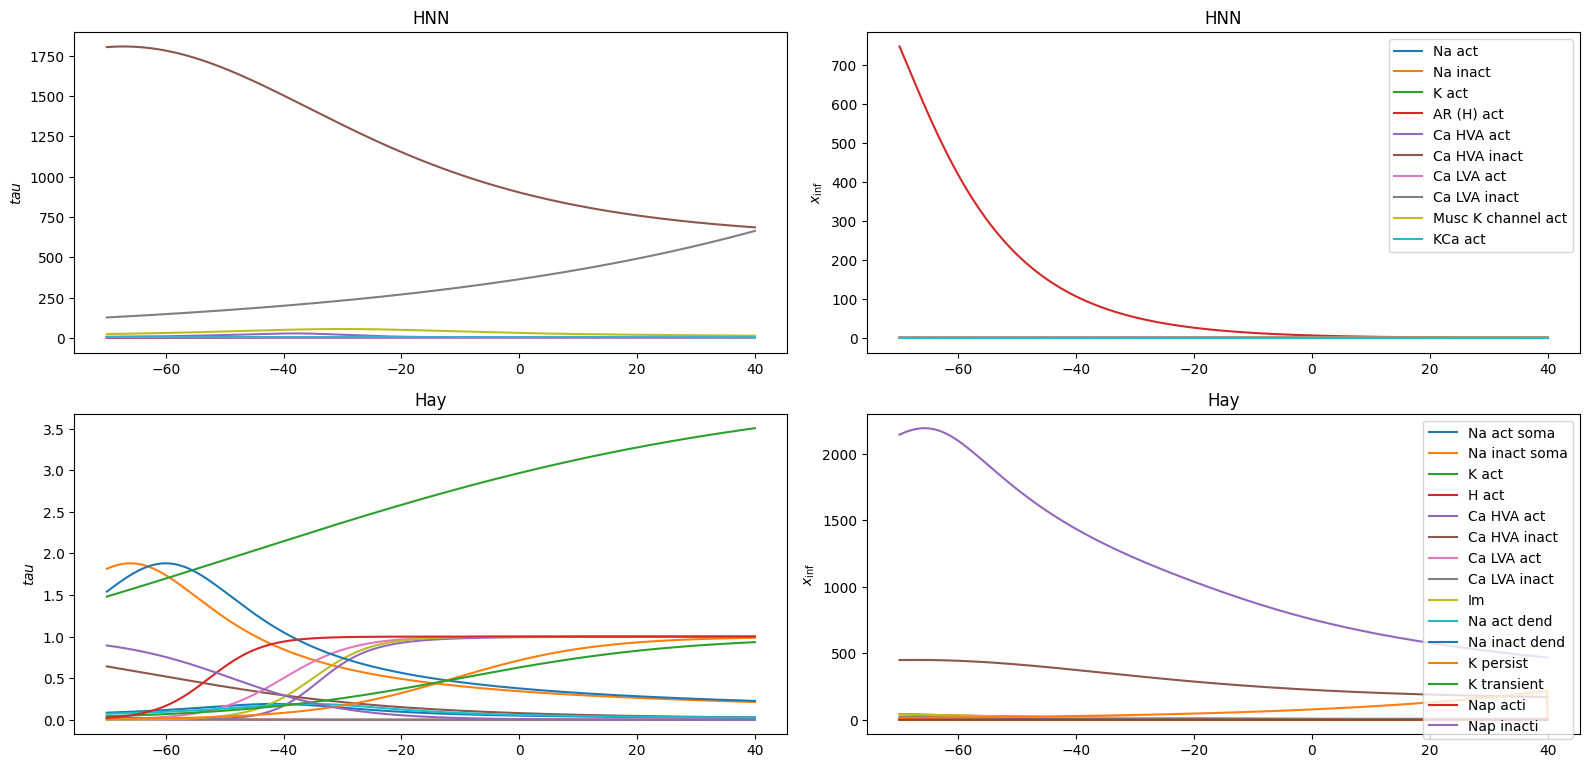

In [30]:
fig, ax = plt.subplots(2,2, figsize=(16,8))

# HNN
ax[0,0].set_title('HNN')
ax[0,0].plot(v_all, mtau_hnn)
ax[0,0].plot(v_all, htau_hnn)
ax[0,0].plot(v_all, ntau_hnn)
ax[0,0].plot(v_all, ar_hnn_tau)
ax[0,0].plot(v_all, ca_m_tau)
ax[0,0].plot(v_all, ca_h_tau)
ax[0,0].plot(v_all, cat_m_tau)
ax[0,0].plot(v_all, cat_h_tau)
ax[0,0].plot(v_all, km_n_tau)
ax[0,0].plot(v_all, kca_n_tau)

ax[0,0].set_ylabel('$tau$')

ax[0,1].set_title('HNN')
ax[0,1].plot(v_all, minf_hnn, label='Na act')
ax[0,1].plot(v_all, hinf_hnn, label='Na inact')
ax[0,1].plot(v_all, ninf_hnn, label='K act')

ax[0,1].plot(v_all, ar_hnn_inf, label='AR (H) act')
ax[0,1].plot(v_all, ca_m_inf, label='Ca HVA act')
ax[0,1].plot(v_all, ca_h_inf, label='Ca HVA inact')
ax[0,1].plot(v_all, cat_m_inf, label='Ca LVA act')
ax[0,1].plot(v_all, cat_h_inf, label='Ca LVA inact')
ax[0,1].plot(v_all, km_n_inf, label='Musc K channel act')
ax[0,1].plot(v_all, kca_n_inf, label='KCa act')

ax[0,1].set_ylabel('$x_{\inf}$')
ax[0,1].legend()
# Hay
ax[1,0].set_title('Hay')
ax[1,0].plot(v_all, mtau_hay_soma)
ax[1,0].plot(v_all, htau_hay_soma)
ax[1,0].plot(v_all, skv31_tau)
ax[1,0].plot(v_all, ih_tau)
ax[1,0].plot(v_all, cahva_m_tau)
ax[1,0].plot(v_all, cahva_h_tau)
ax[1,0].plot(v_all, calva_m_tau)
ax[1,0].plot(v_all, calva_h_tau)
ax[1,0].plot(v_all, im_tau)

ax[1,0].plot(v_all, mtau_hay_dend)
ax[1,0].plot(v_all, htau_hay_dend)
ax[1,0].plot(v_all, kpst_tau)
ax[1,0].plot(v_all, ktst_tau)
ax[1,0].plot(v_all, mtau_hay_nap)
ax[1,0].plot(v_all, htau_hay_nap)

ax[1,0].set_ylabel('$tau$')

ax[1,1].set_title('Hay')
ax[1,1].plot(v_all, minf_hay_soma, label='Na act soma')
ax[1,1].plot(v_all, hinf_hay_soma, label='Na inact soma')
ax[1,1].plot(v_all, skv31_inf, label='K act')
ax[1,1].plot(v_all, ih_inf, label='H act')
ax[1,1].plot(v_all, cahva_m_inf, label='Ca HVA act')
ax[1,1].plot(v_all, cahva_h_inf, label='Ca HVA inact')
ax[1,1].plot(v_all, calva_m_inf, label='Ca LVA act')
ax[1,1].plot(v_all, calva_h_inf, label='Ca LVA inact')
ax[1,1].plot(v_all, ih_inf, label='Im')


ax[1,1].plot(v_all, minf_hay_dend, label='Na act dend')
ax[1,1].plot(v_all, hinf_hay_dend, label='Na inact dend')
ax[1,1].plot(v_all, kpst_inf, label='K persist')
ax[1,1].plot(v_all, ktst_inf, label='K transient')
ax[1,1].plot(v_all, minf_hay_nap, label='Nap acti')
ax[1,1].plot(v_all, hinf_hay_nap, label='Nap inacti')
ax[1,1].set_ylabel('$x_{\inf}$')

ax[1,1].legend()

fig.tight_layout()
fig.savefig(figpth+'HNN_activation_vs_hay.png')

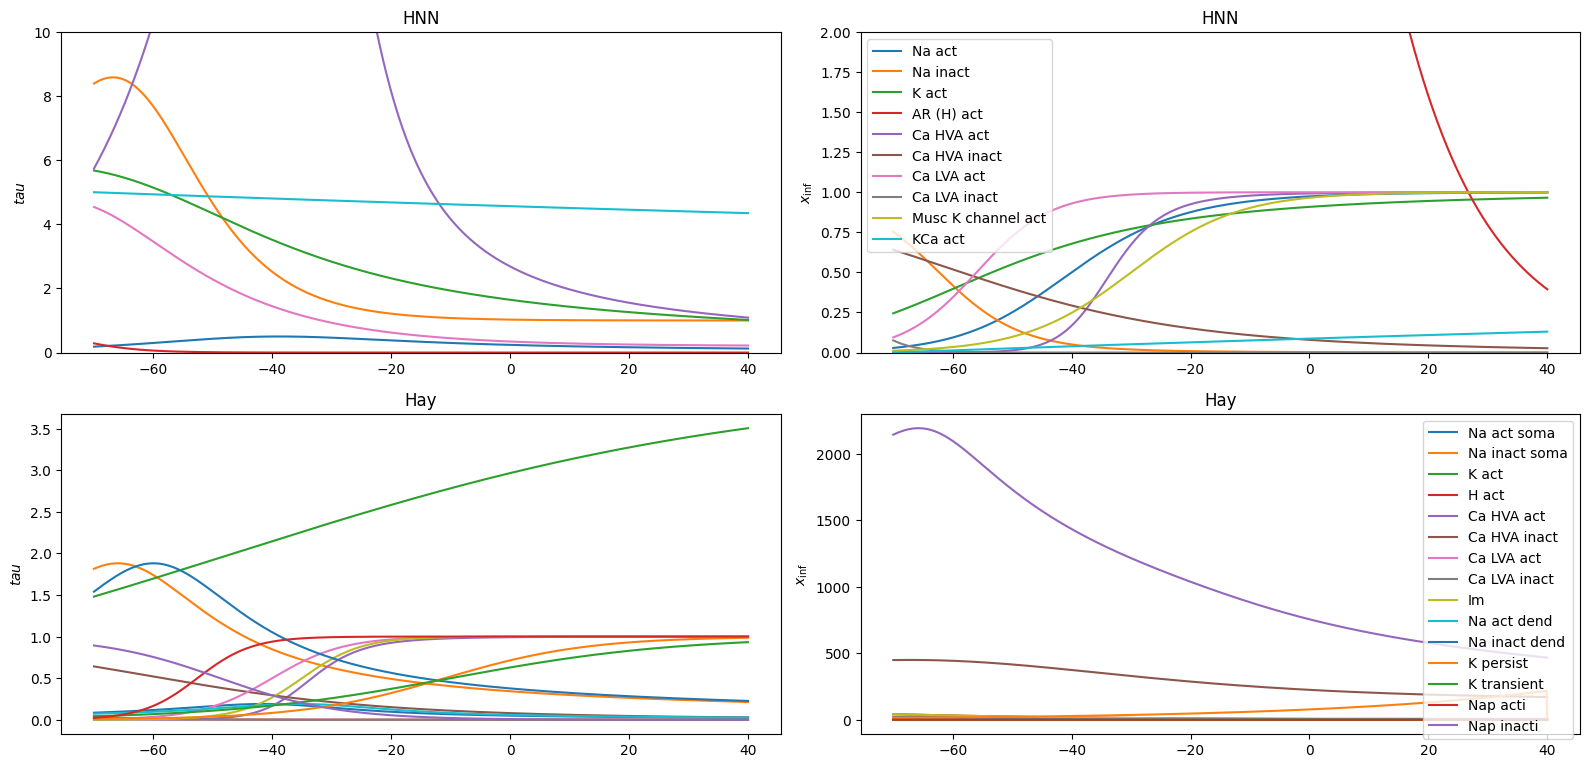

In [34]:
fig, ax = plt.subplots(2,2, figsize=(16,8))

# HNN
ax[0,0].set_title('HNN')
ax[0,0].plot(v_all, mtau_hnn)
ax[0,0].plot(v_all, htau_hnn)
ax[0,0].plot(v_all, ntau_hnn)
ax[0,0].plot(v_all, ar_hnn_tau)
ax[0,0].plot(v_all, ca_m_tau)
ax[0,0].plot(v_all, ca_h_tau)
ax[0,0].plot(v_all, cat_m_tau)
ax[0,0].plot(v_all, cat_h_tau)
ax[0,0].plot(v_all, km_n_tau)
ax[0,0].plot(v_all, kca_n_tau)

ax[0,0].set_ylim([0, 10])
ax[0,0].set_ylabel('$tau$')

ax[0,1].set_title('HNN')
ax[0,1].plot(v_all, minf_hnn, label='Na act')
ax[0,1].plot(v_all, hinf_hnn, label='Na inact')
ax[0,1].plot(v_all, ninf_hnn, label='K act')

ax[0,1].plot(v_all, ar_hnn_inf, label='AR (H) act')
ax[0,1].plot(v_all, ca_m_inf, label='Ca HVA act')
ax[0,1].plot(v_all, ca_h_inf, label='Ca HVA inact')
ax[0,1].plot(v_all, cat_m_inf, label='Ca LVA act')
ax[0,1].plot(v_all, cat_h_inf, label='Ca LVA inact')
ax[0,1].plot(v_all, km_n_inf, label='Musc K channel act')
ax[0,1].plot(v_all, kca_n_inf, label='KCa act')
ax[0,1].set_ylim([0, 2])

ax[0,1].set_ylabel('$x_{\inf}$')
ax[0,1].legend()
# Hay
ax[1,0].set_title('Hay')
ax[1,0].plot(v_all, mtau_hay_soma)
ax[1,0].plot(v_all, htau_hay_soma)
ax[1,0].plot(v_all, skv31_tau)
ax[1,0].plot(v_all, ih_tau)
ax[1,0].plot(v_all, cahva_m_tau)
ax[1,0].plot(v_all, cahva_h_tau)
ax[1,0].plot(v_all, calva_m_tau)
ax[1,0].plot(v_all, calva_h_tau)
ax[1,0].plot(v_all, im_tau)

ax[1,0].plot(v_all, mtau_hay_dend)
ax[1,0].plot(v_all, htau_hay_dend)
ax[1,0].plot(v_all, kpst_tau)
ax[1,0].plot(v_all, ktst_tau)
ax[1,0].plot(v_all, mtau_hay_nap)
ax[1,0].plot(v_all, htau_hay_nap)

ax[1,0].set_ylabel('$tau$')

ax[1,1].set_title('Hay')
ax[1,1].plot(v_all, minf_hay_soma, label='Na act soma')
ax[1,1].plot(v_all, hinf_hay_soma, label='Na inact soma')
ax[1,1].plot(v_all, skv31_inf, label='K act')
ax[1,1].plot(v_all, ih_inf, label='H act')
ax[1,1].plot(v_all, cahva_m_inf, label='Ca HVA act')
ax[1,1].plot(v_all, cahva_h_inf, label='Ca HVA inact')
ax[1,1].plot(v_all, calva_m_inf, label='Ca LVA act')
ax[1,1].plot(v_all, calva_h_inf, label='Ca LVA inact')
ax[1,1].plot(v_all, ih_inf, label='Im')


ax[1,1].plot(v_all, minf_hay_dend, label='Na act dend')
ax[1,1].plot(v_all, hinf_hay_dend, label='Na inact dend')
ax[1,1].plot(v_all, kpst_inf, label='K persist')
ax[1,1].plot(v_all, ktst_inf, label='K transient')
ax[1,1].plot(v_all, minf_hay_nap, label='Nap acti')
ax[1,1].plot(v_all, hinf_hay_nap, label='Nap inacti')
ax[1,1].set_ylabel('$x_{\inf}$')

ax[1,1].legend()

fig.tight_layout()
fig.savefig(figpth+'HNN_activation_vs_hay_without_Im.png')

In [22]:
# fig, ax = plt.subplots(3,2, figsize=(10,8))

# # HNN
# ax[0,0].set_title('HNN HH2')
# ax[0,0].plot(v_all, mtau_hnn)
# ax[0,0].plot(v_all, htau_hnn)
# ax[0,0].plot(v_all, ntau_hnn)
# ax[0,0].set_ylabel('$tau$')

# ax[0,1].set_title('HNN HH2')
# ax[0,1].plot(v_all, minf_hnn)
# ax[0,1].plot(v_all, hinf_hnn)
# ax[0,1].plot(v_all, ninf_hnn)
# ax[0,1].set_ylabel('$x_{\inf}$')


# # HH default
# ax[1,0].set_title('HH default')
# ax[1,0].plot(v_all, mtau_hh)
# ax[1,0].plot(v_all, htau_hh)
# ax[1,0].plot(v_all, ntau_hh)
# ax[1,0].set_ylabel('$tau$')

# ax[1,1].set_title('HH default')
# ax[1,1].plot(v_all, minf_hh)
# ax[1,1].plot(v_all, hinf_hh)
# ax[1,1].plot(v_all, ninf_hh)
# ax[1,1].set_ylabel('$x_{\inf}$')

# # Hay
# ax[2,0].set_title('Hay')
# ax[2,0].plot(v_all, mtau_hay)
# ax[2,0].plot(v_all, htau_hay)
# ax[2,0].plot(v_all, ntau_hay)
# ax[2,0].set_ylabel('$tau$')

# ax[2,1].set_title('Hay')
# ax[2,1].plot(v_all, minf_hay, label='m')
# ax[2,1].plot(v_all, hinf_hay, label='h')
# ax[2,1].plot(v_all, ninf_hay, label='n')
# ax[2,1].legend()
# ax[2,1].set_ylabel('$x_{\inf}$')


# fig.tight_layout()

In [23]:
# adding the Ca-activated K channel reduces spiking massively! No more firing at critical threshold

In [24]:
# fig, ax = plt.subplots(figsize=(4,8))

# yticks = []
# yticklabels = []
# c = 0
# for i,section in enumerate(section_names):
    
#     ax.plot(t,voltg[i] + c, label=section)

#     yticks.append(-75+c)
#     yticks.append(50+c)

#     yticklabels.append(str(np.round(-75)))
#     yticklabels.append(str(np.round(50)))

#     c -= 200


# ax.set_yticks(yticks)
# ax.set_yticklabels(yticklabels)
# ax.set_ylabel('voltage $\mu V$')
# ax.set_xlabel('time (ms)')
# fig.legend()

# fig.savefig('hay_na_kv31_nap_pas_cahva_buffer_calva_SK_E2.png')
    

In [25]:
# # 3 spikes
# l5pyr= Cell(sections, cell_tree, gid=0)
# l5pyr.build()
# l5pyr = add_mechs(l5pyr, nap=True)

# stim = [None]*3

# for i in range(3):
#     stim[i] = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
#     stim[i].delay = 5+(10*i)
#     stim[i].dur = 1
#     stim[i].amp = 1.

# voltg = [None]*len(section_names)
# for i, section in enumerate(section_names):
#     voltg[i] = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)

# t = h.Vector().record(h._ref_t)


# h.celsius = 37
# h.finitialize(-65 * mV)
# h.continuerun(40 * ms)

In [26]:
# fig, ax = plt.subplots(figsize=(4,8))

# yticks = []
# yticklabels = []
# c = 0
# for i,section in enumerate(section_names):
    
#     ax.plot(t,voltg[i] + c, label=section)

#     yticks.append(-75+c)
#     yticks.append(50+c)

#     yticklabels.append(str(np.round(-75)))
#     yticklabels.append(str(np.round(50)))

#     c -= 200


# ax.set_yticks(yticks)
# ax.set_yticklabels(yticklabels)
# ax.set_ylabel('voltage $\mu V$')
# ax.set_xlabel('time (ms)')
# fig.legend()

# fig.savefig('3spikes_all_comps_hay_na_kv31_nap_pas_cahva_buffer_calva_SK_E2.png')